# Aircraft Cargo-Lock Detection with YOLOv5s

**Computer vision project | Object detection, evaluation, and explainability**

This notebook trains a YOLOv5s detector on the **AC Locks** dataset, evaluates predictions against labeled test images, saves visual comparisons, and explores gradient-based explanations with Grad-CAM.

**Workflow:** Setup → Dataset → Training → Evaluation → Prediction gallery → Error analysis → Grad-CAM.

## 1. Environment and dependencies

Designed for Google Colab or a Python environment with a compatible PyTorch installation. GPU acceleration is recommended. The project uses **YOLOv5s**.

In [1]:
# Run once in a fresh notebook environment (uncomment if needed)
%pip install -q "ultralytics>=8.2,<9" "roboflow>=1,<2" "supervision>=0.20,<1" "grad-cam>=1.5,<2" opencv-python matplotlib pyyaml


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from pathlib import Path
import json
import random
import shutil

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"Using device: {DEVICE}")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Device: {DEVICE}")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Using device: cuda
Device: cuda


## 2. Download and inspect the dataset

Source: [AC Locks dataset on Roboflow Universe, version 9](https://universe.roboflow.com/ac-locks/ac-locks/dataset/9).  Follow the dataset license and attribution requirements before redistributing images or annotations. Set `ROBOFLOW_API_KEY` as an environment variable

In [3]:
import os

# optionally retrieve the secret without displaying its value
try:
    from google.colab import userdata
    if not os.getenv("ROBOFLOW_API_KEY"):
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
except (ImportError, KeyError, AttributeError):
    pass

from roboflow import download_dataset
DATASET_URL = "https://universe.roboflow.com/ac-locks/ac-locks/dataset/9"
# Download once, then set DATASET_DIR to the existing dataset directory on later runs
dataset = download_dataset(DATASET_URL, "yolov8")
DATASET_DIR = Path(dataset.location).resolve()
print("Dataset:", DATASET_DIR)


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to AC-locks--9 in yolov8:: 100%|██████████| 1285/1285 [00:00<00:00, 4539.58it/s]

Dataset: /content/AC-locks--9


In [4]:
DATA_YAML = DATASET_DIR / "data.yaml"
with DATA_YAML.open() as f:
    dataset_config = yaml.safe_load(f)
print(yaml.safe_dump(dataset_config, sort_keys=False))
for subset in ("train", "valid", "test"):
    folder = DATASET_DIR / subset / "images"
    if folder.exists():
        print(f"{subset}: {len(list(folder.glob('*')))} image files")


names:
- Lock Down
- Lock Up
nc: 2
roboflow:
  license: CC BY 4.0
  project: ac-locks
  url: https://universe.roboflow.com/ac-locks/ac-locks/dataset/9
  version: 9
  workspace: ac-locks
test: ../test/images
train: ../train/images
val: ../valid/images

train: 501 image files
test: 137 image files


## 3.  train/validation split

Here we **copy** files instead, preserve the original training directory, and use a fixed seed. If Roboflow provides a predefined validation split, you may prefer to retain it rather than creating a new one.

In [6]:
source_images = DATASET_DIR / "train" / "images"
source_labels = DATASET_DIR / "train" / "labels"
if not source_images.is_dir():
    raise FileNotFoundError(f"Expected training images at {source_images}")

image_files = sorted(p for p in source_images.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
if len(image_files) < 2:
    raise ValueError("At least two training images are required for an 80/20 split.")
rng = random.Random(SEED)
rng.shuffle(image_files)
split_at = max(1, min(len(image_files) - 1, int(0.8 * len(image_files))))

for split_name, files in (("train_split", image_files[:split_at]), ("val_split", image_files[split_at:])):
    for kind in ("images", "labels"):
        (DATASET_DIR / split_name / kind).mkdir(parents=True, exist_ok=True)
    for image_path in files:
        shutil.copy2(image_path, DATASET_DIR / split_name / "images" / image_path.name)
        label_path = source_labels / f"{image_path.stem}.txt"
        if label_path.exists():
            shutil.copy2(label_path, DATASET_DIR / split_name / "labels" / label_path.name)

# Use absolute paths so the YAML works regardless of the current working directory
config = dict(dataset_config)
config.pop("path", None)
config["train"] = str(DATASET_DIR / "train_split" / "images")
config["val"] = str(DATASET_DIR / "val_split" / "images")
if (DATASET_DIR / "test" / "images").is_dir():
    config["test"] = str(DATASET_DIR / "test" / "images")
TRAIN_YAML = OUTPUT_DIR / "data_split.yaml"
with TRAIN_YAML.open("w") as f:
    yaml.safe_dump(config, f, sort_keys=False)
print(f"Training images: {split_at}; validation images: {len(image_files) - split_at}")
print("Configuration:", TRAIN_YAML)


Training images: 400; validation images: 101
Configuration: outputs/data_split.yaml


## 4. Train the YOLOv5s detector

Training artifacts are saved under `outputs/training/`; the actual run directory is obtained from the trainer rather than assuming `runs/detect/train`.

In [9]:
model = YOLO("yolov5s.pt")
TRAIN_EPOCHS = 300
# Training can take substantial time
train_results = model.train(
    data=str(TRAIN_YAML),
    epochs=TRAIN_EPOCHS,
    seed=SEED,
    project=str(OUTPUT_DIR / "training"),
    name="yolov5s_cargo_locks",
    exist_ok=True,
    plots=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
print("Best weights:", BEST_WEIGHTS)


PRO TIP 💡 Replace 'model=yolov5s.pt' with new 'model=yolov5su.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=outputs/data_split.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=

## 5. Load a trained checkpoint

If you have already trained the model, you can skip the training cell and point `BEST_WEIGHTS` to your existing `best.pt` file. The notebook does not ship with trained weights.

In [10]:
# Override this path if loading weights from a previous run
BEST_WEIGHTS = globals().get("BEST_WEIGHTS", OUTPUT_DIR / "training" / "yolov5s_cargo_locks" / "weights" / "best.pt")
BEST_WEIGHTS = Path(BEST_WEIGHTS)
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Checkpoint not found: {BEST_WEIGHTS}. Train first or update BEST_WEIGHTS.")
detector = YOLO(str(BEST_WEIGHTS))
print("Loaded checkpoint:", BEST_WEIGHTS)


Loaded checkpoint: /content/runs/detect/outputs/training/yolov5s_cargo_locks/weights/best.pt


## 6. Evaluate on the held-out test set

Use the Ultralytics validation API for consistent precision, recall, and mAP calculations. The test split must remain separate from training and validation. Results are written to a JSON file instead of flooding the notebook with predictions.

In [11]:
if "test" not in config:
    raise ValueError("The dataset configuration has no test split.")
test_metrics = detector.val(data=str(TRAIN_YAML), split="test", plots=True,
                            project=str(OUTPUT_DIR / "evaluation"), name="test", exist_ok=True)
metrics_summary = {
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "map50": float(test_metrics.box.map50),
    "map50_95": float(test_metrics.box.map),
}
(OUTPUT_DIR / "test_metrics.json").write_text(json.dumps(metrics_summary, indent=2))
for key, value in metrics_summary.items():
    print(f"{key}: {value:.4f}")


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5s summary (fused): 84 layers, 9,112,310 parameters, 0 gradients, 23.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 79.8±141.4 MB/s, size: 63.3 KB)
val: Scanning /content/AC-locks--9/test/labels... 137 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 137/137 418.2it/s 0.3s
val: New cache created: /content/AC-locks--9/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.7it/s 3.3s
                   all        137       1094      0.898      0.812      0.838      0.612
             Lock Down         95        510      0.872       0.81      0.831      0.617
               Lock Up        125        584      0.924      0.813      0.845      0.607
Speed: 2.5ms preprocess, 8.9ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/outputs/evaluation/test
precision: 0.8978
recal

## 7. Save predictions and display a small random gallery

All test images are processed and saved to `outputs/predictions/`. Only a **reproducible random sample of six** appears in the notebook. Each gallery row compares predicted boxes with ground-truth labels. The full prediction set is not printed inline.

In [12]:
from PIL import Image

TEST_IMAGES = DATASET_DIR / "test" / "images"
TEST_LABELS = DATASET_DIR / "test" / "labels"
PRED_DIR = OUTPUT_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
image_paths = sorted(p for p in TEST_IMAGES.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
if not image_paths:
    raise ValueError(f"No test images found in {TEST_IMAGES}")

# Run on all test images and save annotated prediction images.
for image_path in image_paths:
    prediction = detector.predict(source=str(image_path), verbose=False)[0]
    annotated_bgr = prediction.plot()
    cv2.imwrite(str(PRED_DIR / f"{image_path.stem}_prediction.jpg"), annotated_bgr)
print(f"Saved {len(image_paths)} annotated predictions in {PRED_DIR}")


Saved 137 annotated predictions in outputs/predictions


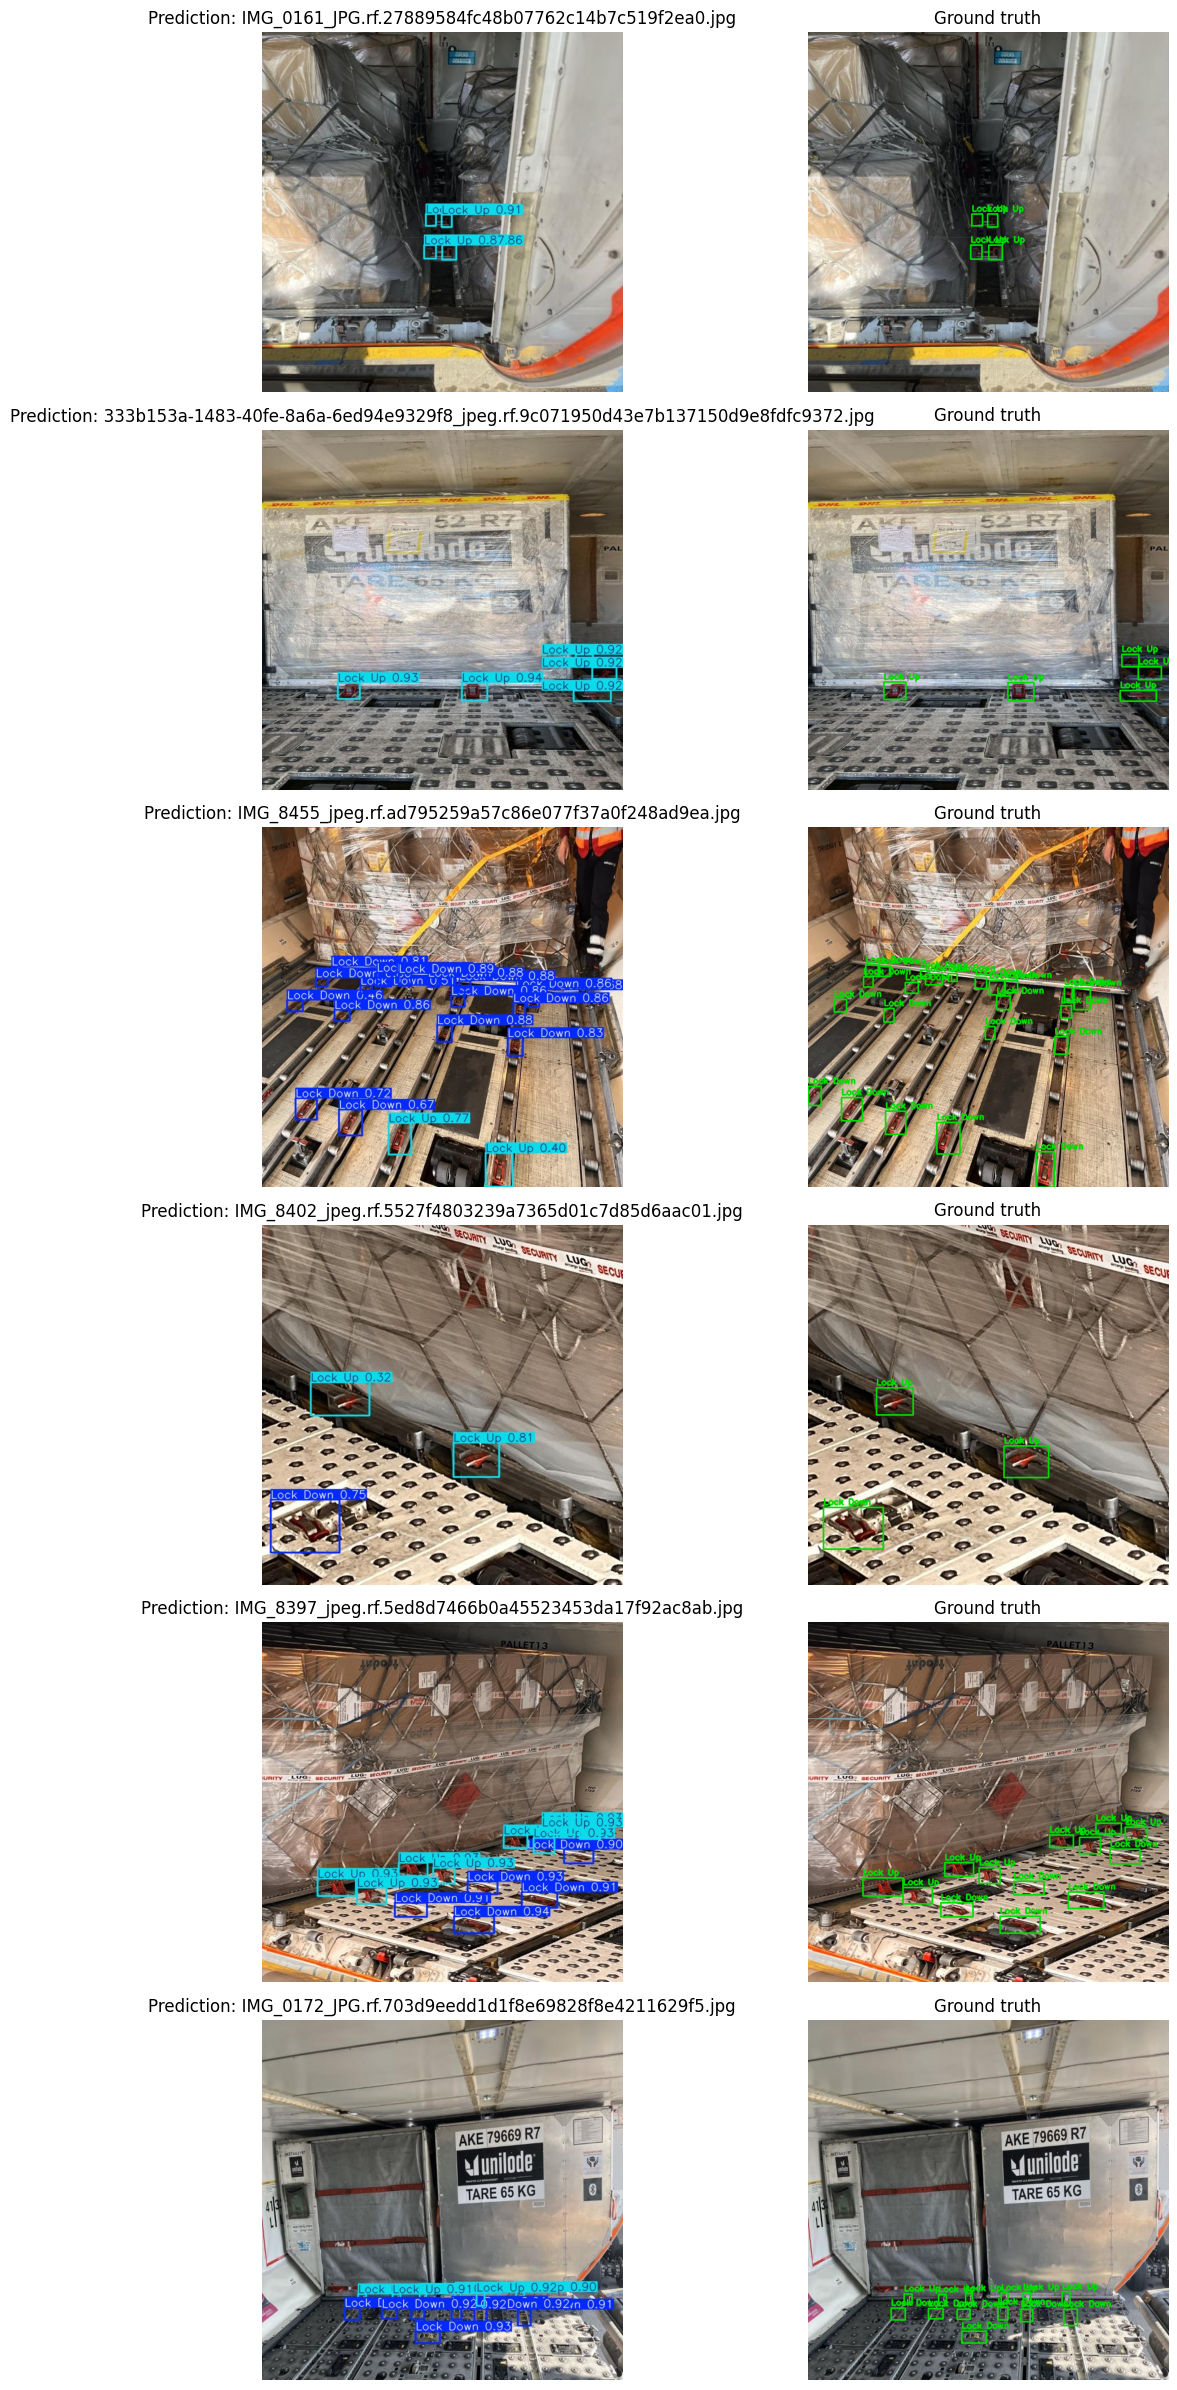

In [13]:
def draw_ground_truth(image_rgb, label_path, class_names):
    """Draw normalized YOLO xywh labels on an RGB image."""
    canvas = image_rgb.copy()
    height, width = canvas.shape[:2]
    if not label_path.exists():
        return canvas
    for line in label_path.read_text().splitlines():
        fields = line.split()
        if len(fields) < 5:
            continue
        class_id = int(float(fields[0]))
        cx, cy, bw, bh = map(float, fields[1:5])
        x1, y1 = int((cx - bw / 2) * width), int((cy - bh / 2) * height)
        x2, y2 = int((cx + bw / 2) * width), int((cy + bh / 2) * height)
        cv2.rectangle(canvas, (x1, y1), (x2, y2), (0, 220, 0), 2)
        label = class_names.get(class_id, str(class_id)) if isinstance(class_names, dict) else class_names[class_id]
        cv2.putText(canvas, str(label), (max(0, x1), max(15, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 220, 0), 2)
    return canvas

SAMPLE_SIZE = min(6, len(image_paths))
sampled_paths = random.Random(SEED).sample(image_paths, SAMPLE_SIZE)
fig, axes = plt.subplots(SAMPLE_SIZE, 2, figsize=(13, 4 * SAMPLE_SIZE), squeeze=False)
for row, image_path in enumerate(sampled_paths):
    original_rgb = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    pred_bgr = cv2.imread(str(PRED_DIR / f"{image_path.stem}_prediction.jpg"))
    pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)
    gt_rgb = draw_ground_truth(original_rgb, TEST_LABELS / f"{image_path.stem}.txt", detector.names)
    axes[row, 0].imshow(pred_rgb)
    axes[row, 0].set_title(f"Prediction: {image_path.name}")
    axes[row, 1].imshow(gt_rgb)
    axes[row, 1].set_title("Ground truth")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_predictions.png", dpi=160, bbox_inches="tight")
plt.show()


## 8. Inspect false-positive detections

A **false positive** is a predicted box that does not match a ground-truth box of the same class at the selected IoU threshold. An image with *any* labels can still contain false-positive boxes. The code below matches predictions to labels greedily, by descending confidence, at IoU ≥ 0.50. This is a diagnostic, not a replacement for official mAP evaluation.

In [14]:
def box_iou(box, boxes):
    if len(boxes) == 0:
        return np.empty(0, dtype=float)
    top_left = np.maximum(box[:2], boxes[:, :2])
    bottom_right = np.minimum(box[2:], boxes[:, 2:])
    wh = np.maximum(0, bottom_right - top_left)
    intersection = wh[:, 0] * wh[:, 1]
    area_a = np.prod(np.maximum(0, box[2:] - box[:2]))
    area_b = np.prod(np.maximum(0, boxes[:, 2:] - boxes[:, :2]), axis=1)
    return intersection / np.maximum(area_a + area_b - intersection, 1e-9)


def read_yolo_labels(label_path, image_width, image_height):
    boxes, classes = [], []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            fields = line.split()
            if len(fields) < 5:
                continue
            cls = int(float(fields[0]))
            cx, cy, bw, bh = map(float, fields[1:5])
            boxes.append([(cx - bw / 2) * image_width, (cy - bh / 2) * image_height,
                          (cx + bw / 2) * image_width, (cy + bh / 2) * image_height])
            classes.append(cls)
    return np.asarray(boxes, dtype=float).reshape(-1, 4), np.asarray(classes, dtype=int)


def find_false_positive_indices(result, gt_boxes, gt_classes, threshold=0.50):
    pred_boxes = result.boxes.xyxy.cpu().numpy()
    pred_classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()
    matched_gt = set()
    false_positive_indices = []
    for i in np.argsort(-confidences):
        candidates = np.array([j for j, cls in enumerate(gt_classes)
                               if cls == pred_classes[i] and j not in matched_gt], dtype=int)
        if len(candidates) == 0:
            false_positive_indices.append(int(i))
            continue
        overlaps = box_iou(pred_boxes[i], gt_boxes[candidates])
        best = int(np.argmax(overlaps))
        if overlaps[best] >= threshold:
            matched_gt.add(int(candidates[best]))
        else:
            false_positive_indices.append(int(i))
    return false_positive_indices

FP_DIR = OUTPUT_DIR / "false_positives"
FP_DIR.mkdir(parents=True, exist_ok=True)
fp_records = []
for image_path in image_paths:
    result = detector.predict(str(image_path), conf=0.25, verbose=False)[0]
    height, width = result.orig_shape
    gt_boxes, gt_classes = read_yolo_labels(TEST_LABELS / f"{image_path.stem}.txt", width, height)
    indices = find_false_positive_indices(result, gt_boxes, gt_classes)
    if not indices:
        continue
    # Draw only the unmatched boxes, not all predictions.
    annotated = result.orig_img.copy()
    for idx in indices:
        x1, y1, x2, y2 = map(int, result.boxes.xyxy[idx].cpu().numpy())
        confidence = float(result.boxes.conf[idx])
        cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(annotated, f"FP {confidence:.2f}", (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2)
    cv2.imwrite(str(FP_DIR / f"{image_path.stem}_fp.jpg"), annotated)
    fp_records.append({"image": image_path.name, "false_positive_boxes": len(indices)})
(OUTPUT_DIR / "false_positive_summary.json").write_text(json.dumps(fp_records, indent=2))
print(f"Images with unmatched predictions: {len(fp_records)}; saved to {FP_DIR}")


Images with unmatched predictions: 52; saved to outputs/false_positives


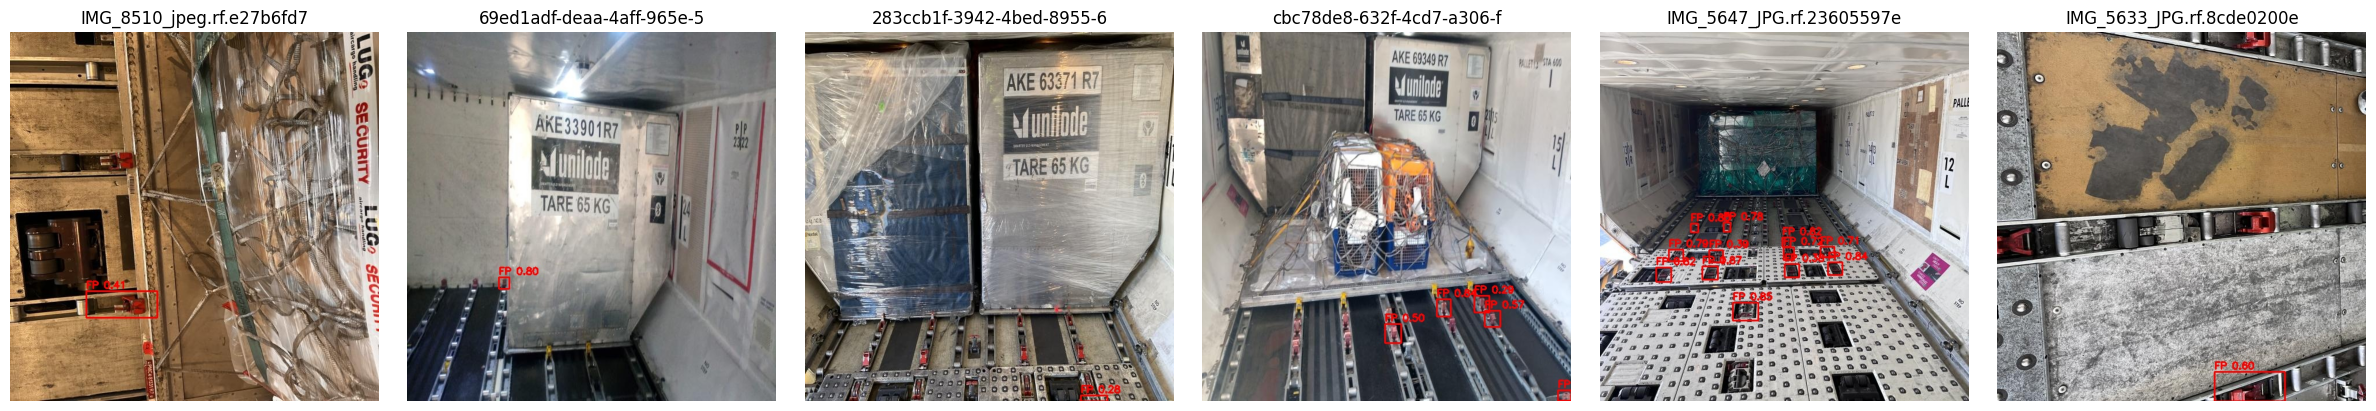

In [15]:
fp_images = sorted(FP_DIR.glob("*_fp.jpg"))
if fp_images:
    examples = random.Random(SEED).sample(fp_images, min(6, len(fp_images)))
    fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4), squeeze=False)
    for ax, path in zip(axes[0], examples):
        ax.imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB))
        ax.set_title(path.stem[:25])
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No unmatched detections at confidence 0.25 and IoU 0.50.")


## 9. Experimental Grad-CAM for YOLOv5s
Here we use **objectness × class probability** and a **single high-confidence pre-NMS proposal** as the differentiable target. We use a convolutional feature layer immediately before the Detect head. This is an *approximate, proposal-level explanation*, not an attribution of a post-NMS box. The model output and target-layer compatibility are checked explicitly; changes to the Ultralytics model API may require adaptation.

**Important:** Grad-CAM input uses a simple square resize for illustration, while Ultralytics inference ordinarily uses letterboxing. Thus the heatmap and normal predictions are not pixel-perfect equivalents. Interpret this visualization qualitatively.

In [18]:
# from pytorch_grad_cam import GradCAM
# from pytorch_grad_cam.utils.image import show_cam_on_image

# raw_model = detector.model.to(DEVICE).eval()
# # Pick the last convolutional feature block before the Detect head.
# # YOLOv5s generally uses a C3 block here; we choose the final Conv2d within it.
# feature_block = raw_model.model[-2]
# conv_layers = [layer for layer in feature_block.modules() if isinstance(layer, torch.nn.Conv2d)]
# if not conv_layers:
#     raise RuntimeError("No Conv2d layer found before the Detect head; inspect model architecture.")
# target_layer = conv_layers[-1]

# class YOLOv5ProposalScore(torch.nn.Module):
#     """Expose a differentiable single-proposal confidence for YOLOv5 inference."""
#     def __init__(self, backbone):
#         super().__init__()
#         self.backbone = backbone

#     def forward(self, x):
#         output = self.backbone(x)
#         pred = output[0] if isinstance(output, (tuple, list)) else output
#         if pred.ndim != 3 or pred.shape[-1] < 6:
#             raise RuntimeError(f"Expected YOLOv5 decoded output [B, N, 5+C], got {tuple(pred.shape)}")
#         confidence = pred[..., 4:5] * pred[..., 5:]
#         # Use the best class-confidence proposal for each image; retain gradients.
#         return confidence.flatten(start_dim=1).amax(dim=1, keepdim=True)

# cam_model = YOLOv5ProposalScore(raw_model).to(DEVICE).eval()
# example_path = sampled_paths[0]
# image_bgr = cv2.imread(str(example_path))
# if image_bgr is None:
#     raise FileNotFoundError(example_path)
# image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
# image_size = 640
# resized_rgb = cv2.resize(image_rgb, (image_size, image_size))
# input_float = resized_rgb.astype(np.float32) / 255.0
# input_tensor = torch.from_numpy(input_float.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)

# with torch.enable_grad():
#     with GradCAM(model=cam_model, target_layers=[target_layer]) as cam:
#         grayscale_cam = cam(input_tensor=input_tensor,targets=None)[0]

# visualization = show_cam_on_image(input_float, grayscale_cam, use_rgb=True)
# fig, axes = plt.subplots(1, 3, figsize=(15, 5))
# for ax, picture, title in zip(axes,
#                               [resized_rgb, grayscale_cam, visualization],
#                               ["Resized input", "Grad-CAM activation", "Grad-CAM overlay"]):
#     ax.imshow(picture, cmap="jet" if picture.ndim == 2 else None)
#     ax.set_title(title)
#     ax.axis("off")
# plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "gradcam_example.png", dpi=160, bbox_inches="tight")
# plt.show()

## 10. Conclusions and limitations

This notebook provides a repeatable pipeline for training and evaluating a cargo-lock detector, saving full prediction outputs, sampling representative comparisons, and inspecting unmatched detections. To assess performance, report the metrics generated in Section 6 after executing the notebook with your trained weights.

**Limitations:** Random image-level splitting may leak information if near-duplicate frames or images from the same aircraft/session occur across splits. The false-positive review uses a simple greedy IoU matcher and is not a substitute for standard evaluation. The Grad-CAM map highlights influential features for a pre-NMS confidence score, not proof that the detector localized the correct physical lock.

**Potential extensions:** Group-aware splitting; per-class error analysis; threshold sensitivity; a letterbox-consistent, box-specific Grad-CAM implementation; inference latency benchmarking.

**Data attribution:** [AC Locks, Roboflow Universe (version 9)](https://universe.roboflow.com/ac-locks/ac-locks/dataset/9). Verify its license before publishing any data samples.